# Boston 311 Hackathon
### Data preparation, monthly demand forecast and sensitivity analysis

We use the 2023 and 2024 Boston 311 request files to estimate monthly demand for 2025. The forecast covers Public Works, Transportation, Parks & Recreation, and Inspectional Services. We also test how demand changes under the baseline, 20% lower, and 20% higher scenarios.

The monthly forecasts and sensitivity results are shared with the staffing model and the Intake-to-Plan Pipeline.

## 1. Load the data

Place the 2023 and 2024 CSV files beside this notebook, or inside a folder named `data`. Only the columns needed for this analysis are loaded.

In [1]:
from pathlib import Path
from collections import Counter
from math import ceil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

codes = ["PWDx", "BTDT", "PARK", "ISD"]
names = {"PWDx": "Public Works", "BTDT": "Transportation",
         "PARK": "Parks & Recreation", "ISD": "Inspectional Services"}
capacity_per_day = {"PWDx": 12, "BTDT": 15, "PARK": 6, "ISD": 4}
workdays = 21
output_dir = Path("Boston311_Team_Outputs")
output_dir.mkdir(exist_ok=True)

def find_file(year):
    name = f"lagan_311_open_data_{year}_rvsd3"
    for folder in [Path("data"), Path(".")]:
        for filename in [f"{name}.csv", f"{name}(1).csv", f"boston_311_{year}.csv"]:
            file = folder / filename
            if file.is_file():
                return file
    raise FileNotFoundError(f"Place the {year} Boston 311 CSV beside the notebook or in data/")

files = {year: find_file(year) for year in [2023, 2024]}
for year, file in files.items():
    print(year, file.name)

c:\Users\taten\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


2023 lagan_311_open_data_2023_rvsd3.csv
2024 lagan_311_open_data_2024_rvsd3.csv


## 2. Prepare the monthly data

Requests are counted using `open_dt`, since we want to forecast when requests arrive. We keep the four departments and preserve the original request types and queues. We process the large files in chunks.

In [2]:
def prepare_year(file, year):
    monthly_counts = Counter()
    catalog_counts = Counter()
    seen_ids = set()
    raw_rows = 0
    kept_rows = 0
    invalid_dates = 0
    duplicates = 0

    columns = ["case_enquiry_id", "open_dt", "department", "type", "queue"]
    reader = pd.read_csv(file, usecols=columns, dtype=str, chunksize=50000,
                         encoding="utf-8-sig")

    for chunk in reader:
        raw_rows += len(chunk)
        dates = pd.to_datetime(chunk["open_dt"], format="mixed", errors="coerce")
        dept = chunk["department"].str.strip()
        invalid_dates += int(dates.isna().sum())

        valid = dates.dt.year.eq(year) & dept.isin(codes)
        part = chunk.loc[valid].copy()
        part["department"] = dept.loc[valid]
        part["month"] = dates.loc[valid].dt.to_period("M").dt.to_timestamp()

        # Keep one record per request ID
        ids = part["case_enquiry_id"].fillna("").str.strip()
        repeated = ids.ne("") & (ids.isin(seen_ids) | ids.duplicated())
        duplicates += int(repeated.sum())
        seen_ids.update(ids.loc[ids.ne("") & ~repeated])
        part = part.loc[~repeated]
        kept_rows += len(part)

        for key, count in part.groupby(["month", "department"]).size().items():
            monthly_counts[key] += int(count)

        if year == 2024:
            for col in ["type", "queue"]:
                part[col] = part[col].fillna("<MISSING>").str.strip().replace("", "<MISSING>")
            for key, count in part.groupby(["department", "type", "queue"]).size().items():
                catalog_counts[key] += int(count)

    monthly = pd.DataFrame([
        {"month": month, "year": year, "month_number": month.month,
         "department": dept, "requests": monthly_counts[(month, dept)]}
        for month in pd.date_range(f"{year}-01-01", periods=12, freq="MS")
        for dept in codes
    ])
    catalog = pd.DataFrame([
        {"department": d, "type": t, "queue": q, "requests_2024": n}
        for (d, t, q), n in sorted(catalog_counts.items())
    ], columns=["department", "type", "queue", "requests_2024"])
    checks = {"year": year, "raw_requests": raw_rows, "selected_requests": kept_rows,
              "invalid_open_dates": invalid_dates, "duplicate_ids_removed": duplicates}
    return monthly, catalog, checks

histories = []
checks = []
for year in [2023, 2024]:
    monthly, catalog, check = prepare_year(files[year], year)
    histories.append(monthly)
    checks.append(check)
    if year == 2024:
        type_catalog = catalog

historical = pd.concat(histories, ignore_index=True)
quality = pd.DataFrame(checks)
print("Monthly historical rows:", len(historical))
display(quality)
display(historical.groupby(["year", "department"])["requests"].sum().unstack())

Monthly historical rows: 96


,year,raw_requests,selected_requests,invalid_open_dates,duplicate_ids_removed
0,2023,307791,282246,0,0
1,2024,306756,276417,0,0


department,BTDT,ISD,PARK,PWDx
year,,,,
2023,75314,18123,17541,171268
2024,81447,18624,18736,157610


## 3. Forecast monthly demand for 2025

For each department, we estimate 2025 annual demand using half of the 2023-to-2024 growth rate on a multiplicative scale, with the growth factor capped between 0.85 and 1.15. We then split that annual estimate across months using 65% of the 2024 seasonal pattern and 35% of the 2023 pattern.

These are forecasting assumptions rather than rules supplied by the brief.

In [3]:
def forecast_department(history, department):
    part = history.loc[history["department"] == department]
    y23 = part.loc[part["year"] == 2023].sort_values("month_number")["requests"].to_numpy()
    y24 = part.loc[part["year"] == 2024].sort_values("month_number")["requests"].to_numpy()

    total23, total24 = y23.sum(), y24.sum()
    growth = np.clip(np.sqrt(total24 / total23), 0.85, 1.15)
    annual_estimate = int(np.floor(total24 * growth + 0.5))
    seasonal_share = 0.35 * (y23 / total23) + 0.65 * (y24 / total24)

    # Round monthly values while keeping the annual total unchanged
    unrounded = annual_estimate * seasonal_share
    forecast = np.floor(unrounded).astype(int)
    remainder = annual_estimate - forecast.sum()
    forecast[np.argsort(-(unrounded - forecast))[:remainder]] += 1

    return pd.DataFrame({
        "month": pd.date_range("2025-01-01", periods=12, freq="MS"),
        "department": department,
        "forecast_requests": forecast,
        "requests_2023_same_month": y23,
        "requests_2024_same_month": y24,
        "seasonal_share": seasonal_share,
        "growth_factor_applied": growth
    })

forecast = pd.concat([forecast_department(historical, d) for d in codes], ignore_index=True)
forecast = forecast.sort_values(["month", "department"]).reset_index(drop=True)

monthly_table = forecast.pivot(index="month", columns="department", values="forecast_requests")
monthly_table = monthly_table[codes]
monthly_table["Total"] = monthly_table.sum(axis=1)
print("Monthly forecast for 2025")
display(monthly_table.rename(index=lambda x: x.strftime("%b %Y")))

annual_summary = historical.groupby(["year", "department"])["requests"].sum().unstack().T
annual_summary["Forecast 2025"] = forecast.groupby("department")["forecast_requests"].sum()
annual_summary.columns = ["Actual 2023", "Actual 2024", "Forecast 2025"]
print("Annual totals")
display(annual_summary.loc[codes])
assert len(forecast) == 48

Monthly forecast for 2025


department,PWDx,BTDT,PARK,ISD,Total
month,,,,,
Jan 2025,12437,6039,919,1459,20854
Feb 2025,10285,6117,785,1501,18688
Mar 2025,11995,7584,1219,1336,22134
Apr 2025,12740,7155,1486,1370,22751
May 2025,13031,7729,2173,1530,24463
Jun 2025,12673,7481,2829,1801,24784
Jul 2025,13678,6685,2662,1762,24787
Aug 2025,16474,7090,2360,1997,27921
Sep 2025,15662,7990,1658,1804,27114


Annual totals


,Actual 2023,Actual 2024,Forecast 2025
department,,,
PWDx,171268,157610,151195
BTDT,75314,81447,84698
PARK,17541,18736,19364
ISD,18123,18624,18880


## 4. Monthly forecast chart

This chart shows the baseline 2025 forecast for each department separately.

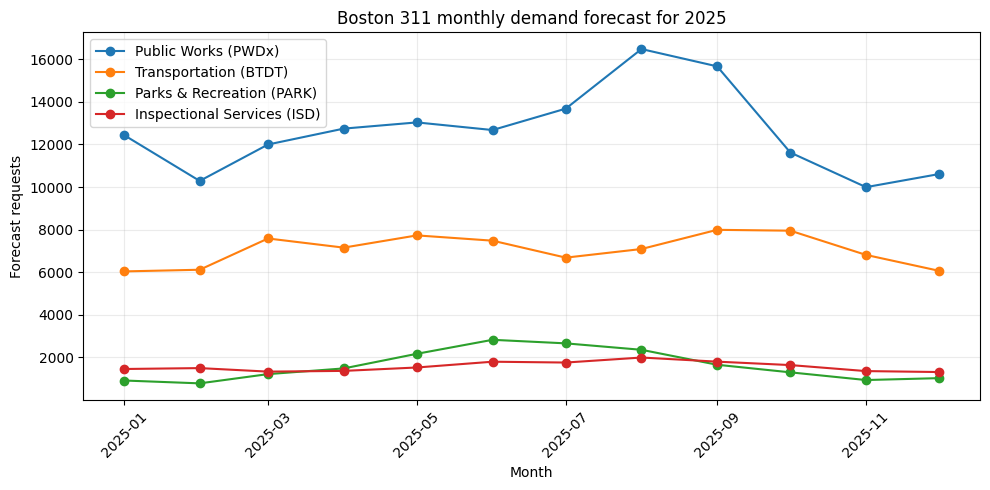

In [4]:
plt.figure(figsize=(10, 5))
for department in codes:
    values = forecast.loc[forecast["department"] == department].sort_values("month")
    plt.plot(values["month"], values["forecast_requests"], marker="o",
             label=f"{names[department]} ({department})")

plt.title("Boston 311 monthly demand forecast for 2025")
plt.xlabel("Month")
plt.ylabel("Forecast requests")
plt.legend()
plt.grid(alpha=0.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(output_dir / "monthly_forecast_by_department_2025.png", dpi=160)
plt.show()

## 5. Historical comparison

We compare each month in 2024 with the same month in 2023 as a simple historical reference. This checks how much demand changed between years. It is not an independent accuracy test of the final 2025 forecast.

In [5]:
comparison = []
for department in codes:
    rows = historical.loc[historical["department"] == department]
    previous = rows.loc[rows["year"] == 2023].sort_values("month_number")["requests"].to_numpy()
    actual = rows.loc[rows["year"] == 2024].sort_values("month_number")["requests"].to_numpy()
    wape = np.abs(actual - previous).sum() / actual.sum()
    comparison.append({"department": department, "historical_WAPE_pct": round(wape * 100, 2)})

backtest = pd.DataFrame(comparison)
display(backtest)

,department,historical_WAPE_pct
0,PWDx,13.76
1,BTDT,7.79
2,PARK,15.91
3,ISD,12.69


## 6. Department shares and request catalog

We use the full year of 2024 for the base shares. 


In [6]:
share_data = type_catalog.loc[
    ~type_catalog["type"].str.contains("general comments", case=False, na=False)
]
share_counts = (share_data.groupby("department")["requests_2024"]
                .sum().reindex(codes, fill_value=0))
base_shares = pd.DataFrame({
    "department": codes,
    "eligible_requests_2024": share_counts.values,
    "base_share": (share_counts / share_counts.sum()).values,
    "excluded_general_comments": True
})
print("Full-year 2024 department shares")
display(base_shares)
print("Request catalog entries:", len(type_catalog))

Full-year 2024 department shares


,department,eligible_requests_2024,base_share,excluded_general_comments
0,PWDx,157082,0.570537,True
1,BTDT,80971,0.294095,True
2,PARK,18650,0.067739,True
3,ISD,18620,0.067630,True


Request catalog entries: 1575


## 7. Sensitivity analysis

We test three demand levels for every month and department: baseline, 20% lower and 20% higher. The crew calculation is a simple capacity requirement based on 21 workdays per month. It does not include the hiring delays, backlog or release decisions handled by the staffing model.

In [7]:
scenarios = {"Low (-20%)": 0.8, "Baseline": 1.0, "High (+20%)": 1.2}
scenario_rows = []

for row in forecast.itertuples(index=False):
    monthly_capacity = workdays * capacity_per_day[row.department]
    baseline_crews = ceil(row.forecast_requests / monthly_capacity)
    for label, multiplier in scenarios.items():
        demand = int(np.floor(row.forecast_requests * multiplier + 0.5))
        crews = ceil(demand / monthly_capacity)
        scenario_rows.append({
            "month": row.month,
            "department": row.department,
            "scenario": label,
            "demand_multiplier": multiplier,
            "baseline_forecast_requests": row.forecast_requests,
            "scenario_requests": demand,
            "change_vs_baseline_requests": demand - row.forecast_requests,
            "crew_capacity_per_month": monthly_capacity,
            "capacity_floor_crews": crews,
            "change_in_capacity_floor_crews": crews - baseline_crews
        })

sensitivity = pd.DataFrame(scenario_rows)
sensitivity = sensitivity.sort_values(["scenario", "month", "department"]).reset_index(drop=True)
scenario_totals = sensitivity.groupby("scenario")["scenario_requests"].sum()
print("2025 demand by scenario")
display(scenario_totals.reindex(scenarios.keys()).to_frame("requests"))
assert len(sensitivity) == 144

2025 demand by scenario


,requests
scenario,
Low (-20%),219309
Baseline,274137
High (+20%),328965


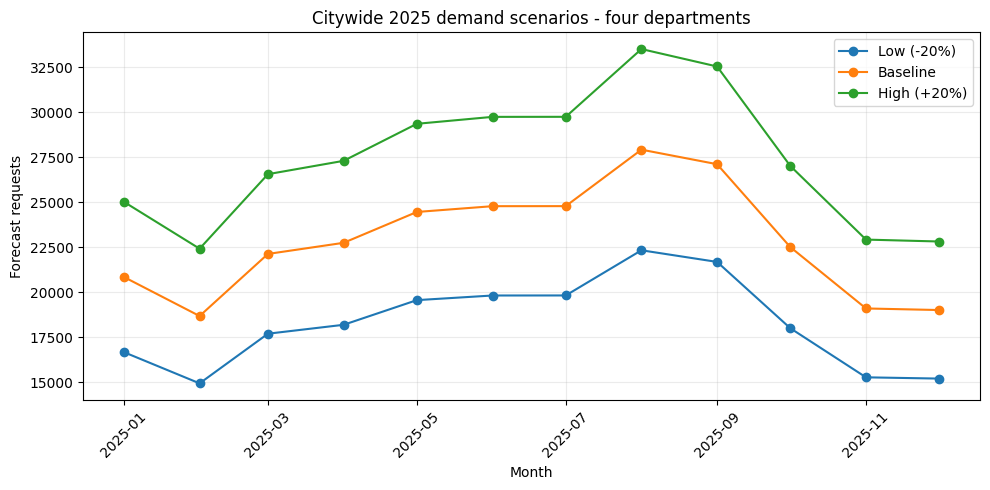

In [8]:
plt.figure(figsize=(10, 5))
for label in ["Low (-20%)", "Baseline", "High (+20%)"]:
    values = (sensitivity.loc[sensitivity["scenario"] == label]
              .groupby("month")["scenario_requests"].sum().sort_index())
    plt.plot(values.index, values.values, marker="o", label=label)

plt.title("Citywide 2025 demand scenarios - four departments")
plt.xlabel("Month")
plt.ylabel("Forecast requests")
plt.legend()
plt.grid(alpha=0.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(output_dir / "sensitivity_2025_monthly.png", dpi=160)
plt.show()

## 8. Save files for the team

The forecast and scenario files are used by the staffing model. The department shares and request catalog are used for the Intake-to-Plan Pipeline and Intake Assistant.

In [8]:
historical.to_csv(output_dir / "historical_monthly_2023_2024.csv", index=False)
forecast.to_csv(output_dir / "monthly_forecast_2025.csv", index=False)
sensitivity.to_csv(output_dir / "sensitivity_scenarios_2025.csv", index=False)
base_shares.to_csv(output_dir / "department_base_shares_2024.csv", index=False)
type_catalog.to_csv(output_dir / "type_queue_catalog_2024.csv", index=False)
quality.to_csv(output_dir / "data_quality_checks.csv", index=False)
backtest.to_csv(output_dir / "seasonal_naive_backtest.csv", index=False)
monthly_table.to_csv(output_dir / "monthly_forecast_2025_wide.csv")

print("Files saved in:", output_dir.resolve())
print("2025 forecast rows:", len(forecast))
print("Sensitivity rows:", len(sensitivity))

Files saved in: C:\Users\taten\Downloads\Boston311_Team_Outputs
2025 forecast rows: 48
Sensitivity rows: 144
